# Previsão de Pontuação no Fantasy Premier League

**SME0828 - Introdução à Ciência de Dados** | Prof. Francisco Rodrigues

| Integrante | NUSP |
|:---|:---|
| Artur Kenzo | xxxxxxx |
| Daniel Jorge | 15446861 |
| Luis Henrique | xxxxxxx |

---

**Base de dados:** [`vaastav/Fantasy-Premier-League`](https://github.com/vaastav/Fantasy-Premier-League) - arquivo `merged_gw.csv`

## Questão Fundamental e Hipótese

> "É possível prever com precisão a pontuação de um jogador na próxima rodada da Premier League utilizando seu histórico recente de desempenho e a força defensiva/ofensiva do adversário?"

**Hipótese:** Modelos baseados em árvores (Random Forest e XGBoost/LightGBM) usando médias móveis (rolling features) e métricas de dificuldade do adversário superam modelos lineares e baselines simples, embora a alta variância de eventos raros (gols, cartões) limite o $R^2$.

**Divisão temporal (sem vazamento):**
- **Treino:** Rodadas 1 a 28
- **Teste:** Rodadas 29 a 38

---

## Etapa 1 - Preparação, Limpeza e Engenharia de Atributos (Anti-Leakage)

Nesta etapa realizamos:

1. **[1.1]** Carregamento e ordenação temporal dos dados
2. **[1.2]** Remoção de atributos irrelevantes e tratamento de vazamento (data leakage)
3. **[1.3]** Dados faltantes e rodadas duplas (Double Gameweeks)
4. **[1.4]** Criação de features históricas com médias móveis (janelas de 3 e 5 rodadas)
5. **[1.5]** Features de contexto do adversário (força ofensiva/defensiva histórica)
6. **[1.6]** Validação anti-leakage e resumo final

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

print('Bibliotecas carregadas com sucesso.')

Bibliotecas carregadas com sucesso.


In [2]:
# Configuração ──────────────────────────────────────────────────────────────
SEASON = '2024-25'

MERGED_GW_URL = (
    'https://raw.githubusercontent.com/vaastav/Fantasy-Premier-League/'
    f'master/data/{SEASON}/gws/merged_gw.csv'
)
TEAMS_URL = (
    'https://raw.githubusercontent.com/vaastav/Fantasy-Premier-League/'
    f'master/data/{SEASON}/teams.csv'
)

# Janelas para as médias móveis históricas
ROLLING_WINDOWS = [3, 5]

# Colunas de estatísticas de jogo usadas como base para as rolling features
ROLLING_BASE_COLS = [
    'total_points', 'minutes', 'ict_index', 'threat', 'creativity',
    'expected_goals', 'expected_assists', 'goals_scored', 'assists',
    'clean_sheets', 'bonus',
]

print(f'Temporada : {SEASON}')
print(f'URL dados : {MERGED_GW_URL}')

Temporada : 2024-25
URL dados : https://raw.githubusercontent.com/vaastav/Fantasy-Premier-League/master/data/2024-25/gws/merged_gw.csv


### 1.1 - Carregamento e Inspeção Inicial

In [3]:
print(f'Carregando dados da temporada {SEASON}...\n')

df_raw = pd.read_csv(MERGED_GW_URL)
df_teams = pd.read_csv(TEAMS_URL)

n_rows, n_cols = df_raw.shape
n_teams = df_teams.shape[0]
print(f'  merged_gw : {n_rows:,} linhas x {n_cols} colunas')
print(f'  teams     : {n_teams} times')
print('\nColunas disponíveis:')
print(df_raw.columns.tolist())

Carregando dados da temporada 2024-25...

  merged_gw : 27,605 linhas x 49 colunas
  teams     : 20 times

Colunas disponíveis:
['name', 'position', 'team', 'xP', 'assists', 'bonus', 'bps', 'clean_sheets', 'creativity', 'element', 'expected_assists', 'expected_goal_involvements', 'expected_goals', 'expected_goals_conceded', 'fixture', 'goals_conceded', 'goals_scored', 'ict_index', 'influence', 'kickoff_time', 'minutes', 'mng_clean_sheets', 'mng_draw', 'mng_goals_scored', 'mng_loss', 'mng_underdog_draw', 'mng_underdog_win', 'mng_win', 'modified', 'opponent_team', 'own_goals', 'penalties_missed', 'penalties_saved', 'red_cards', 'round', 'saves', 'selected', 'starts', 'team_a_score', 'team_h_score', 'threat', 'total_points', 'transfers_balance', 'transfers_in', 'transfers_out', 'value', 'was_home', 'yellow_cards', 'GW']


In [4]:
print('=== Tipos de dados ===')
print(df_raw.dtypes.to_string())
print('\n=== Amostra dos dados ===')
display(df_raw.head(5))
print('\n=== Distribuição do alvo: total_points ===')
print(df_raw['total_points'].describe())
print('\n=== Valores ausentes (colunas com NaN) ===')
missing = df_raw.isnull().sum()
missing_nz = missing[missing > 0].sort_values(ascending=False)
if len(missing_nz) > 0:
    print(missing_nz.to_string())
else:
    print('Nenhum valor ausente encontrado.')

=== Tipos de dados ===
name                           object
position                       object
team                           object
xP                            float64
assists                         int64
bonus                           int64
bps                             int64
clean_sheets                    int64
creativity                    float64
element                         int64
expected_assists              float64
expected_goal_involvements    float64
expected_goals                float64
expected_goals_conceded       float64
fixture                         int64
goals_conceded                  int64
goals_scored                    int64
ict_index                     float64
influence                     float64
kickoff_time                   object
minutes                         int64
mng_clean_sheets              float64
mng_draw                      float64
mng_goals_scored              float64
mng_loss                      float64
mng_underdog_draw          

,name,position,team,xP,assists,bonus,bps,clean_sheets,creativity,element,...,team_h_score,threat,total_points,transfers_balance,transfers_in,transfers_out,value,was_home,yellow_cards,GW
0,Alex Scott,MID,Bournemouth,1.6,0,0,11,0,12.8,77,...,1,0.0,2,0,0,0,50,False,0,1
1,Carlos Miguel dos Santos Pereira,GK,Nott'm Forest,2.2,0,0,0,0,0.0,427,...,1,0.0,0,0,0,0,45,True,0,1
2,Tomiyasu Takehiro,DEF,Arsenal,0.0,0,0,0,0,0.0,22,...,2,0.0,0,0,0,0,50,True,0,1
3,Malcolm Ebiowei,MID,Crystal Palace,0.0,0,0,0,0,0.0,197,...,2,0.0,0,0,0,0,45,False,0,1
4,Ben Brereton Díaz,MID,Southampton,1.0,0,0,-2,0,14.0,584,...,1,16.0,1,0,0,0,55,False,1,1



=== Distribuição do alvo: total_points ===
count    27605.000000
mean         1.200906
std          2.416882
min         -5.000000
25%          0.000000
50%          0.000000
75%          1.000000
max         25.000000
Name: total_points, dtype: float64

=== Valores ausentes (colunas com NaN) ===
mng_clean_sheets     14178
mng_draw             14178
mng_goals_scored     14178
mng_loss             14178
mng_underdog_draw    14178
mng_underdog_win     14178
mng_win              14178


### 1.1 - Ordenação Temporal

É necessário ordenar estritamente por jogador (`element`) e rodada (`round`) para as features históricas que serão criadas a seguir. Sem essa ordenação, as médias móveis com `.shift(1)` capturariam dados de rodadas erradas.

In [5]:
df = df_raw.copy()
df = df.sort_values(['element', 'round']).reset_index(drop=True)

rmin = df['round'].min()
rmax = df['round'].max()
n_jogadores = df['element'].nunique()

print('DataFrame ordenado por [element, round].')
print(f'  Rodadas disponíveis  : {rmin} a {rmax}')
print(f'  Jogadores únicos     : {n_jogadores:,}')
print(f'  Total de observações : {len(df):,}')

DataFrame ordenado por [element, round].
  Rodadas disponíveis  : 1 a 38
  Jogadores únicos     : 804
  Total de observações : 27,605


### 1.2 - Remoção de Atributos e Tratamento de Vazamento (Data Leakage)

Vazamento de dados ocorre quando informações do momento `t` (que ainda não existiriam ao se fazer a previsão) são usadas como features para prever `t`. Os principais casos aqui são:

| Coluna | Problema | Solução |
|:---|:---|:---|
| `team_h_score`, `team_a_score` | Placar do jogo atual | Extrair info útil e remover |
| `xP` | Viés de lookahead documentado no repositório da base de dados | Aplicar `.shift(1)` => `xP_lag1` |
| `name`, `kickoff_time`, `fixture` | Identificadores textuais sem valor preditivo | Remover |

In [6]:
# Derivar gols marcados/sofridos pelo time do jogador em cada partida antes de descartar as colunas de placar
if 'team_h_score' in df.columns and 'team_a_score' in df.columns:
    df['team_goals_scored'] = np.where(
        df['was_home'] == True, df['team_h_score'], df['team_a_score']
    )
    df['team_goals_conceded_match'] = np.where(
        df['was_home'] == True, df['team_a_score'], df['team_h_score']
    )
    print('Derivadas: team_goals_scored | team_goals_conceded_match')

# xP com shift(1): transforma xP[t] em xP da rodada anterior (sem vazamento)
if 'xP' in df.columns:
    df['xP_lag1'] = df.groupby('element')['xP'].shift(1)
    print('Derivada : xP_lag1 (xP defasada 1 rodada)')

# Extrair estatísticas por time e partida (fixture) antes de descartar 'fixture'
# Preserva informações de Double Gameweeks (uma linha por jogo, não por rodada)
if 'fixture' in df.columns:
    team_game_stats = (
        df[['team', 'round', 'fixture', 'team_goals_scored', 'team_goals_conceded_match']]
        .drop_duplicates(subset=['team', 'fixture'])
        .sort_values(['team', 'round'])
        .reset_index(drop=True)
    )
    print(f'\nEstatísticas de jogo extraídas: {len(team_game_stats)} registros (time x partida)')
else:
    team_game_stats = (
        df[['team', 'round', 'team_goals_scored', 'team_goals_conceded_match']]
        .drop_duplicates(subset=['team', 'round'])
        .sort_values(['team', 'round'])
        .reset_index(drop=True)
    )
    print(f'\nEstatísticas de rodada extraídas: {len(team_game_stats)} registros')

# Remover colunas com vazamento direto ou unicamente identificadoras
COLS_TO_DROP = [
    'name',                        # identificador textual (mantemos element)
    'kickoff_time',                # após ordenação, não agrega informação
    'fixture',                     # redundante com (round, opponent_team)
    'team_h_score',                # placar do jogo atual => vazamento direto
    'team_a_score',                # placar do jogo atual => vazamento direto
    'xP',                          # substituído por xP_lag1
    'team_goals_scored',           # resultado do jogo atual => vazamento
    'team_goals_conceded_match',   # resultado do jogo atual => vazamento
]
cols_removed = [c for c in COLS_TO_DROP if c in df.columns]
df.drop(columns=cols_removed, inplace=True)

print(f'\nColunas removidas: {cols_removed}')
print(f'Shape atual: {df.shape}')

Derivadas: team_goals_scored | team_goals_conceded_match
Derivada : xP_lag1 (xP defasada 1 rodada)

Estatísticas de jogo extraídas: 760 registros (time x partida)

Colunas removidas: ['name', 'kickoff_time', 'fixture', 'team_h_score', 'team_a_score', 'xP', 'team_goals_scored', 'team_goals_conceded_match']
Shape atual: (27605, 44)


### 1.3 - Dados Faltantes e Rodadas Duplas (*Double Gameweeks*)

Dois casos especiais precisam de atenção:

- **Jogadores no banco (`minutes == 0`):** estatísticas de jogo ausentes são zero, então colocamos `0`.
- **Double Gameweeks:** jogadores jogam duas partidas na mesma rodada, gerando duas linhas para o mesmo `(element, round)`. Resolvemos somando as estatísticas acumulativas (pontos, minutos, gols…) e mantendo o último valor para atributos contextuais (posição, preço, adversário).

In [7]:
# Preenchimento de zeros para jogadores que não jogaram
STAT_COLS_ZERO = [
    'goals_scored', 'assists', 'clean_sheets', 'goals_conceded', 'own_goals',
    'penalties_saved', 'penalties_missed', 'yellow_cards', 'red_cards', 'saves',
    'bonus', 'bps', 'expected_goals', 'expected_assists',
    'expected_goal_involvements', 'expected_goals_conceded',
    'influence', 'creativity', 'threat', 'ict_index',
]
stat_zero_present = [c for c in STAT_COLS_ZERO if c in df.columns]
mask_bench = df['minutes'] == 0
n_imputed = 0
for col in stat_zero_present:
    n_nan = df.loc[mask_bench, col].isna().sum()
    if n_nan > 0:
        df.loc[mask_bench & df[col].isna(), col] = 0
        n_imputed += n_nan
print(f'Imputação com 0 (jogadores no banco): {n_imputed} valores preenchidos')

# Rodadas Duplas
double_gw = df.groupby(['element', 'round']).size()
double_gw_cases = double_gw[double_gw > 1]
n_double = len(double_gw_cases)
print(f'\nDouble Gameweeks detectados: {n_double} pares (element, round)')
if n_double > 0:
    print('\nAmostra:')
    print(double_gw_cases.head(5).to_string())

# Agregação: somar estatísticas acumulativas; 'last' para atributos contextuais
SUM_COLS = {
    'total_points', 'minutes', 'goals_scored', 'assists', 'clean_sheets',
    'own_goals', 'penalties_saved', 'penalties_missed', 'yellow_cards',
    'red_cards', 'saves', 'bonus', 'bps', 'goals_conceded',
    'expected_goals', 'expected_assists', 'expected_goal_involvements',
    'expected_goals_conceded', 'transfers_in', 'transfers_out', 'transfers_balance',
}
agg_dict = {}
for col in df.columns:
    if col in ('element', 'round'):
        continue
    agg_dict[col] = 'sum' if col in SUM_COLS else 'last'

df = df.groupby(['element', 'round'], as_index=False).agg(agg_dict)
df = df.sort_values(['element', 'round']).reset_index(drop=True)

n_nan_total = df.isnull().sum().sum()
print(f'\nShape após tratamento: {df.shape}')
print(f'NaN totais restantes : {n_nan_total}')

Imputação com 0 (jogadores no banco): 0 valores preenchidos

Double Gameweeks detectados: 374 pares (element, round)

Amostra:
element  round
1        33       2
2        33       2
3        33       2
4        33       2
5        33       2

Shape após tratamento: (27231, 44)
NaN totais restantes : 100048


### 1.4 - Features Históricas com Médias Móveis (Rolling Features)

Para cada estatística de jogo $f$ e janela $w \in \{3, 5\}$ rodadas, criamos:

$$f_{\text{roll}w}[t] = \frac{1}{w} \sum_{k=1}^{w} f[t-k]$$

O `.shift(1)` antes do `.rolling()` garante que a janela use apenas rodadas anteriores a $t$, eliminando qualquer vazamento da rodada atual. `min_periods=1` permite calcular mesmo nas primeiras rodadas (histórico insuficiente).

In [8]:
rolling_base_present = [c for c in ROLLING_BASE_COLS if c in df.columns]

for feat in rolling_base_present:
    for w in ROLLING_WINDOWS:
        col_name = f'{feat}_roll{w}'
        df[col_name] = (
            df.groupby('element')[feat]
            .transform(lambda x, window=w: x.shift(1).rolling(window, min_periods=1).mean())
        )

# Lag-1 direto: pontuação e minutos da rodada imedatamente anterior
for feat in ['total_points', 'minutes']:
    if feat in df.columns:
        df[f'{feat}_lag1'] = df.groupby('element')[feat].shift(1)

created_roll = [f'{f}_roll{w}' for f in rolling_base_present for w in ROLLING_WINDOWS]
created_lag  = [f'{f}_lag1' for f in ['total_points', 'minutes'] if f in df.columns]

print(f'Rolling features criadas : {len(created_roll)}')
print(f'  Exemplo: {created_roll[:4]}')
print(f'Lag features criadas     : {len(created_lag)}')
print(f'  Exemplo: {created_lag}')
print(f'\nShape atual: {df.shape}')

Rolling features criadas : 22
  Exemplo: ['total_points_roll3', 'total_points_roll5', 'minutes_roll3', 'minutes_roll5']
Lag features criadas     : 2
  Exemplo: ['total_points_lag1', 'minutes_lag1']

Shape atual: (27231, 68)


### 1.5 - Features de Contexto do Adversário

Para cada adversário e rodada $t$, calculamos a média histórica acumulada (até $t-1$) de:

- `opp_avg_goals_scored` => força ofensiva do adversário (gols marcados por jogo)
- `opp_avg_goals_conceded` => vulnerabilidade defensiva do adversário (gols sofridos por jogo)

Usamos `expanding().mean()` com `.shift(1)` sobre a série de cada time, de forma que apenas informação histórica entra na feature.

In [9]:
team_game_stats = team_game_stats.sort_values(['team', 'round'])

team_game_stats['opp_avg_goals_scored'] = (
    team_game_stats.groupby('team')['team_goals_scored']
    .transform(lambda x: x.shift(1).expanding(min_periods=1).mean())
)
team_game_stats['opp_avg_goals_conceded'] = (
    team_game_stats.groupby('team')['team_goals_conceded_match']
    .transform(lambda x: x.shift(1).expanding(min_periods=1).mean())
)

# Converter o nome do time (texto) para o ID usado em opponent_team
team_id_map = df_teams.set_index('name')['id'].to_dict()
team_game_stats['team_id'] = team_game_stats['team'].map(team_id_map)

if team_game_stats['team_id'].isna().any():
    nomes_sem_id = sorted(team_game_stats.loc[team_game_stats['team_id'].isna(), 'team'].dropna().unique())
    print(f'Aviso: times sem ID encontrado em df_teams: {nomes_sem_id}')

# Agregar por (team_id, round) para lidar com Double Gameweeks na série de times
opp_context = (
    team_game_stats
    .dropna(subset=['team_id'])
    .groupby(['team_id', 'round'])[['opp_avg_goals_scored', 'opp_avg_goals_conceded']]
    .mean()
    .reset_index()
    .rename(columns={'team_id': 'opponent_team'})
)

# Garantir que ambas as chaves tenham o mesmo tipo inteiro e a mesma codificação de ID usada pela base FPL
df['opponent_team'] = pd.to_numeric(df['opponent_team'], errors='coerce').astype('Int64')
opp_context['opponent_team'] = pd.to_numeric(opp_context['opponent_team'], errors='coerce').astype('Int64')
df['round'] = pd.to_numeric(df['round'], errors='coerce').astype('int64')
opp_context['round'] = pd.to_numeric(opp_context['round'], errors='coerce').astype('int64')

# Merge: o opponent_team de um jogador na rodada t recebe o contexto histórico do adversário
df = df.merge(opp_context, on=['opponent_team', 'round'], how='left', validate='many_to_one')

print('Features de contexto do adversário adicionadas:')
print('  opp_avg_goals_scored   -> força ofensiva do adversário')
print('  opp_avg_goals_conceded -> vulnerabilidade defensiva do adversário')
print(f'\nShape final: {df.shape}')
print(f"Linhas sem contexto do adversário: {df['opp_avg_goals_scored'].isna().sum():,}")
display(
    df[['element', 'round', 'opponent_team', 'was_home',
        'opp_avg_goals_scored', 'opp_avg_goals_conceded']].head(10)
)

Features de contexto do adversário adicionadas:
  opp_avg_goals_scored   -> força ofensiva do adversário
  opp_avg_goals_conceded -> vulnerabilidade defensiva do adversário

Shape final: (27231, 70)
Linhas sem contexto do adversário: 616


,element,round,opponent_team,was_home,opp_avg_goals_scored,opp_avg_goals_conceded
0,1,1,20,True,NaN,NaN
1,1,2,2,False,2.000000,1.000000
2,1,3,5,True,2.500000,0.500000
3,1,4,18,False,2.000000,1.000000
4,1,5,13,False,2.750000,0.750000
5,1,6,11,True,1.200000,1.600000
6,1,7,17,True,0.500000,2.000000
7,1,8,3,False,1.142857,1.428571
8,1,9,12,True,1.875000,0.375000
9,1,10,15,False,1.000000,1.111111


### 1.6 - Validação Anti-Leakage

Verificamos automaticamente que `total_points_lag1[i]` é exatamente `total_points[i-1]` para cada jogador, confirmando que nenhuma informação da rodada atual contaminou as features históricas.

In [10]:
# Exibir a série de um jogador específico para inspeção visual
top_player = df['element'].value_counts().idxmax()
player_df = (
    df[df['element'] == top_player]
    [['element', 'round', 'total_points', 'total_points_lag1',
      'total_points_roll3', 'total_points_roll5']]
    .head(10)
    .reset_index(drop=True)
)
print(f'Verificação anti-leakage — jogador element={top_player}:')
print('Esperado: total_points_lag1[i] == total_points[i-1]\n')
display(player_df)

# Checagem automática para todos os jogadores
df_sorted = df.sort_values(['element', 'round'])

def check_lag(g):
    if len(g) < 2:
        return True
    lag  = g['total_points_lag1'].iloc[1:].values
    prev = g['total_points'].iloc[:-1].values
    mask = ~(pd.isna(lag) & pd.isna(prev))
    if mask.sum() == 0:
        return True
    return np.allclose(lag[mask], prev[mask])

lag_ok = df_sorted.groupby('element').apply(check_lag)
all_ok = lag_ok.all()
status = 'OK - sem vazamento detectado' if all_ok else 'ERRO - verificar pipeline!'
print(f'\nConsistência do lag1 para todos os jogadores: {status}')

Verificação anti-leakage — jogador element=616:
Esperado: total_points_lag1[i] == total_points[i-1]



,element,round,total_points,total_points_lag1,total_points_roll3,total_points_roll5
0,616,1,0,NaN,NaN,NaN
1,616,2,0,0.0,0.0,0.0
2,616,3,0,0.0,0.0,0.0
3,616,4,0,0.0,0.0,0.0
4,616,5,0,0.0,0.0,0.0
5,616,6,0,0.0,0.0,0.0
6,616,7,0,0.0,0.0,0.0
7,616,8,0,0.0,0.0,0.0
8,616,9,0,0.0,0.0,0.0
9,616,10,0,0.0,0.0,0.0



Consistência do lag1 para todos os jogadores: OK - sem vazamento detectado


### 1.7 - Resumo Final da Etapa 1

In [11]:
rolling_cols  = [c for c in df.columns if '_roll' in c or '_lag1' in c]
context_cols  = [c for c in ['was_home', 'opp_avg_goals_scored', 'opp_avg_goals_conceded'] if c in df.columns]
pre_game_cols = [c for c in ['value', 'selected', 'transfers_in', 'transfers_out',
                              'transfers_balance', 'xP_lag1'] if c in df.columns]

rmin = df['round'].min()
rmax = df['round'].max()
n_jog = df['element'].nunique()

print('=' * 56)
print('  RESUMO - PASSO 1: PREPARAÇÃO DOS DADOS')
print('=' * 56)
print(f'\nShape final              : {df.shape}')
print(f'Rodadas                  : {rmin} a {rmax}')
print(f'Jogadores únicos         : {n_jog:,}')
print(f'\nColunas identificadoras  : element, round, team, position, opponent_team')
print(f'Target                   : total_points')
print(f'Features pré-jogo ({len(pre_game_cols)})   : {pre_game_cols}')
print(f'Rolling / lag ({len(rolling_cols)})       : {rolling_cols[:6]}...')
print(f'Contexto adversário ({len(context_cols)}) : {context_cols}')
print(f'\nNaN em rolling features (1ª rodada sem histórico suficiente):')
nan_rolling = df[rolling_cols].isnull().sum()
nan_nz = nan_rolling[nan_rolling > 0]
if len(nan_nz) > 0:
    print(nan_nz.to_string())
else:
    print('  Nenhum NaN detectado.')

# Salvar o dataframe preparado em CSV para uso nos próximos passos
df.to_csv('fpl_prepared.csv', index=False)
print(f'\nDados salvos em fpl_prepared.csv')

  RESUMO - PASSO 1: PREPARAÇÃO DOS DADOS

Shape final              : (27231, 70)
Rodadas                  : 1 a 38
Jogadores únicos         : 804

Colunas identificadoras  : element, round, team, position, opponent_team
Target                   : total_points
Features pré-jogo (6)   : ['value', 'selected', 'transfers_in', 'transfers_out', 'transfers_balance', 'xP_lag1']
Rolling / lag (25)       : ['xP_lag1', 'total_points_roll3', 'total_points_roll5', 'minutes_roll3', 'minutes_roll5', 'ict_index_roll3']...
Contexto adversário (3) : ['was_home', 'opp_avg_goals_scored', 'opp_avg_goals_conceded']

NaN em rolling features (1ª rodada sem histórico suficiente):
xP_lag1                   802
total_points_roll3        804
total_points_roll5        804
minutes_roll3             804
minutes_roll5             804
ict_index_roll3           804
ict_index_roll5           804
threat_roll3              804
threat_roll5              804
creativity_roll3          804
creativity_roll5          804
expect

---

## Etapa 2 - Descrição Estatística dos Dados

Nesta etapa analisamos a distribuição estatística da variável alvo (`total_points`) e das principais *features* geradas na Etapa 1:

1. **[2.1]** Estatísticas descritivas gerais (média, mediana, desvio padrão, quartis, assimetria e curtose)
2. **[2.2]** Estatísticas descritivas separadas por posição (`GK`, `DEF`, `MID`, `FWD` e `AM`)
3. **[2.3]** Concentração em zeros, *outliers* e comparação entre todos os registros e jogadores em campo (`minutes > 0`)
4. **[2.4]** Síntese das observações estatísticas

### 2.1 - Estatísticas Descritivas Gerais

Carregamos `fpl_prepared.csv` (caso ainda não esteja em memória) e calculamos as métricas descritivas para `total_points` e para as principais *features* pré-jogo, móveis (*rolling*) e de contexto do adversário.

In [12]:
import pandas as pd
import numpy as np

if 'df' not in globals():
    df = pd.read_csv('fpl_prepared.csv')

key_cols = [
    'total_points', 'minutes', 'value', 'xP_lag1',
    'total_points_roll3', 'total_points_roll5', 'minutes_roll3',
    'ict_index_roll3', 'threat_roll3', 'creativity_roll3',
    'expected_goals_roll3', 'expected_assists_roll3',
    'opp_avg_goals_scored', 'opp_avg_goals_conceded'
]

desc_geral = df[key_cols].describe().T
desc_geral['median'] = df[key_cols].median()
desc_geral['iqr'] = desc_geral['75%'] - desc_geral['25%']
desc_geral['skew'] = df[key_cols].skew()
desc_geral['kurtosis'] = df[key_cols].kurtosis()

cols_order = ['count', 'mean', 'std', 'min', '25%', 'median', '75%', 'max', 'iqr', 'skew', 'kurtosis']
display(desc_geral[cols_order].round(3))

,count,mean,std,min,25%,median,75%,max,iqr,skew,kurtosis
total_points,27231.0,1.217,2.467,-5.0,0.000,0.000,1.000,29.000,1.000,3.203,13.125
minutes,27231.0,27.486,38.716,0.0,0.000,0.000,72.000,180.000,72.000,0.937,-0.686
value,27231.0,48.579,11.143,5.0,44.000,45.000,51.000,154.000,7.000,2.403,17.532
xP_lag1,26429.0,1.105,1.903,-2.2,0.000,0.000,1.700,26.400,1.700,2.523,11.154
total_points_roll3,26427.0,1.219,1.928,-2.0,0.000,0.333,1.667,21.000,1.667,2.321,7.335
total_points_roll5,26427.0,1.219,1.791,-2.0,0.000,0.400,2.000,20.500,2.000,2.119,6.355
minutes_roll3,26427.0,27.633,35.391,0.0,0.000,1.333,60.000,150.000,60.000,0.846,-0.878
ict_index_roll3,26427.0,1.441,2.253,0.0,0.000,0.033,2.333,22.800,2.333,2.139,5.848
threat_roll3,26427.0,3.867,8.324,0.0,0.000,0.000,3.667,111.667,3.667,3.331,14.673
creativity_roll3,26427.0,4.277,8.178,0.0,0.000,0.000,5.300,89.650,5.300,2.793,9.887


### 2.2 - Estatísticas Descritivas por Posição

Avaliamos `total_points` e as principais *features* agrupadas por `position` (`GK`, `DEF`, `MID`, `FWD` e `AM` - *Assistant Manager*, chip introduzido na temporada 2024–25).

In [13]:
pos_target = (
    df.groupby('position')['total_points']
    .agg(
        count='count',
        mean='mean',
        std='std',
        min='min',
        q25=lambda s: s.quantile(0.25),
        median='median',
        q75=lambda s: s.quantile(0.75),
        max='max',
        skew='skew',
        kurtosis=lambda s: s.kurtosis()
    )
    .sort_values('mean', ascending=False)
)
pos_target['iqr'] = pos_target['q75'] - pos_target['q25']

print('=== total_points por posição ===')
display(pos_target.round(3))

pos_feats = (
    df.groupby('position')[['value', 'minutes_roll3', 'ict_index_roll3',
                            'expected_goals_roll3', 'expected_assists_roll3']]
    .agg(['mean', 'median', 'std'])
)
print('\n=== Principais features por posição (média, mediana, desvio padrão) ===')
display(pos_feats.round(3))

=== total_points por posição ===


,count,mean,std,min,q25,median,q75,max,skew,kurtosis,iqr
position,,,,,,,,,,,
AM,312,5.965,5.544,0,1.0,5.0,9.0,23,0.764,0.060,8.0
FWD,2984,1.367,2.765,-2,0.0,0.0,1.0,21,2.822,8.484,1.0
MID,12084,1.279,2.425,-2,0.0,0.0,2.0,29,3.458,16.236,2.0
DEF,9024,1.021,2.164,-5,0.0,0.0,1.0,17,2.858,9.332,1.0
GK,2827,0.901,2.079,-2,0.0,0.0,1.0,16,3.047,10.330,1.0



=== Principais features por posição (média, mediana, desvio padrão) ===


value                minutes_roll3                ict_index_roll3  \
            mean median     std          mean median     std            mean   
position                                                                       
AM         9.705    9.5   3.700         0.000  0.000   0.000           0.000   
DEF       44.088   43.0   5.072        30.753  2.667  37.496           1.215   
FWD       57.124   54.0  15.007        23.429  0.333  32.396           1.729   
GK        42.915   41.0   4.091        24.326  0.000  38.272           0.686   
MID       52.150   49.0  10.410        27.803  7.000  33.716           1.751   

                       expected_goals_roll3                \
         median    std                 mean median    std   
position                                                    
AM        0.000  0.000                0.000    0.0  0.000   
DEF       0.067  1.704                0.016    0.0  0.043   
FWD       0.000  2.803                0.109    0.0  0.202   
GK        0.000  1.164                0.000    0.0  0.001   
MID       0.300  2.583                0.052    0.0  0.116   

         expected_assists_roll3                
                           mean median    std  
position                                       
AM                        0.000    0.0  0.000  
DEF                       0.019    0.0  0.046  
FWD                       0.018    0.0  0.045  
GK                        0.000    0.0  0.004  
MID                       0.040    0.0  0.078

### 2.3 - Concentração em Zeros, Outliers e Jogadores Ativos (`minutes > 0`)

No Fantasy Premier League, grande parte dos atletas listados não entra em campo na rodada. Medimos a proporção de zeros (`total_points == 0` e `minutes == 0`), a faixa de pontuação baixa (`total_points <= 2`), os *outliers* positivos (`total_points >= 10`) e repetimos o `describe()` considerando apenas jogadores que atuaram (`minutes > 0`).

In [14]:
# Proporções gerais
n_total = len(df)
pct_zero_pts = (df['total_points'] == 0).mean() * 100
pct_low_pts  = (df['total_points'] <= 2).mean() * 100
pct_haul     = (df['total_points'] >= 10).mean() * 100
pct_zero_min = (df['minutes'] == 0).mean() * 100

print('=== Concentração e Outliers (Base Completa) ===')
print(f'Total de observações      : {n_total:,}')
print(f'minutes == 0              : {pct_zero_min:.2f}%')
print(f'total_points == 0         : {pct_zero_pts:.2f}%')
print(f'total_points <= 2         : {pct_low_pts:.2f}%')
print(f'total_points >= 10 (hauls): {pct_haul:.2f}%') # obs.: "haul" é um termo do FPL para pontuação >= 10 em uma rodada

# Por posição
pos_zero_haul = (
    df.groupby('position')
    .agg(
        pct_min_zero=('minutes', lambda s: (s == 0).mean() * 100),
        pct_pts_zero=('total_points', lambda s: (s == 0).mean() * 100),
        pct_pts_10plus=('total_points', lambda s: (s >= 10).mean() * 100),
    )
    .sort_values('pct_pts_zero', ascending=False)
)
print('\n=== Concentração de zeros e hauls por posição (%) ===')
display(pos_zero_haul.round(2))

# Comparação entre todos e apenas quem jogou (minutes > 0)
df_active = df[df['minutes'] > 0]
comp_active = pd.DataFrame({
    'Base completa': df['total_points'].describe(),
    'Apenas minutes > 0': df_active['total_points'].describe()
}).T
comp_active['skew'] = [df['total_points'].skew(), df_active['total_points'].skew()]
comp_active['kurtosis'] = [df['total_points'].kurtosis(), df_active['total_points'].kurtosis()]

print('\n=== total_points: Base completa vs. Jogadores em campo (minutes > 0) ===')
display(comp_active.round(3))

=== Concentração e Outliers (Base Completa) ===
Total de observações      : 27,231
minutes == 0              : 58.02%
total_points == 0         : 59.62%
total_points <= 2         : 87.11%
total_points >= 10 (hauls): 1.90%

=== Concentração de zeros e hauls por posição (%) ===


,pct_min_zero,pct_pts_zero,pct_pts_10plus
position,,,
GK,73.12,74.11,1.10
DEF,58.50,63.26,0.89
FWD,57.84,59.32,2.45
MID,53.10,54.55,2.14
AM,100.00,22.44,24.36



=== total_points: Base completa vs. Jogadores em campo (minutes > 0) ===


,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
Base completa,27231.0,1.217,2.467,-5.0,0.0,0.0,1.0,29.0,3.203,13.125
Apenas minutes > 0,11431.0,2.737,2.954,-5.0,1.0,2.0,3.0,29.0,2.146,5.999


### 2.4 - Síntese das Observações Estatísticas

- **Forte assimetria à direita e excesso de zeros:** Na base completa (`27.231` observações), `total_points` tem média `1,217`, desvio padrão `2,467`, mediana `0,0` e 3º quartil `1,0` (`skew = 3,203`, `kurtosis = 13,125`). Cerca de `59,62%` das linhas têm `0` pontos (reflexo de `58,02%` com `minutes == 0`) e `87,11%` ficam em até `2` pontos, enquanto apenas `1,90%` atingem `10` ou mais pontos (caracterizados como *hauls* no contexto do FPL).
- **Impacto da minutagem:** Quando filtramos apenas jogadores que entraram em campo (`minutes > 0`), a média de `total_points` mais que dobra, a mediana sobe para acima de zero e a assimetria cai consideravelmente, reforçando `minutes_roll3` como uma *feature* crítica para modelagem.
- **Diferenças entre posições:** Entre as quatro posições tradicionais (`GK`, `DEF`, `MID`, `FWD`), a mediana de `total_points` na base completa é `0,0` em todas, mas a média cresce de `GK` (`0,901`) e `DEF` (`1,021`) para `MID` (`1,279`) e `FWD` (`1,367`). A categoria `AM` (*Assistant Manager*, `312` registros) apresenta comportamento diferente, com média `5,965` e mediana `5,0`.
- **Variáveis de contexto do adversário:** `opp_avg_goals_scored` (`skew = -0,035`) e `opp_avg_goals_conceded` (`skew = 0,512`) têm distribuições bem mais simétricas que as estatísticas individuais dos jogadores (`expected_goals_roll3` com `skew = 4,702`).

---

## Etapa 3 - Análise Exploratória e Padrões Relevantes

Nesta etapa investigamos visualmente os principais padrões da base preparada (`fpl_prepared.csv`):

1. **[3.1]** Distribuição da variável alvo (`total_points`), concentração em `0–2` pontos e cauda longa
2. **[3.2]** Matriz de correlação das *features* defasadas e contextuais com `total_points`
3. **[3.3]** Evolução temporal da pontuação média por faixa de preço (`value`) ao longo das 38 rodadas
4. **[3.4]** Impacto do mando de campo (`was_home`) e da posição (`position`)
5. **[3.5]** Síntese dos padrões identificados

### 3.1 - Distribuição da Variável Alvo (`total_points`)

Comparamos a distribuição completa de `total_points` (evidenciando o excesso de zeros e a cauda longa acima de `15` pontos) com o recorte de jogadores que efetivamente entraram em campo (`minutes > 0`).

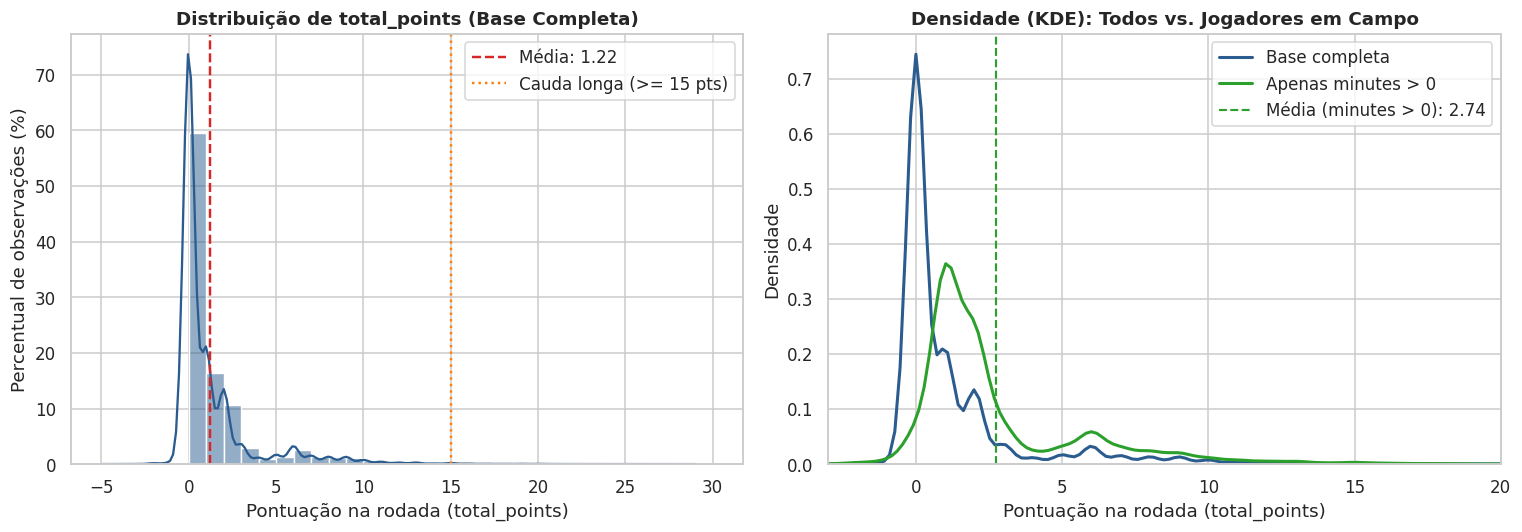

Observações com >= 15 pontos: 115 (0.42%)


In [15]:
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

if 'df' not in globals():
    df = pd.read_csv('fpl_prepared.csv')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Distribuição completa
sns.histplot(
    df['total_points'], bins=range(-5, 31), stat='percent',
    kde=True, color='#2b5c8f', edgecolor='white', ax=axes[0]
)
axes[0].axvline(df['total_points'].mean(), color='#d62728', linestyle='--', linewidth=1.6,
                label=f"Média: {df['total_points'].mean():.2f}")
axes[0].axvline(15, color='#ff7f0e', linestyle=':', linewidth=1.6,
                label='Cauda longa (>= 15 pts)')
axes[0].set_title('Distribuição de total_points (Base Completa)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Pontuação na rodada (total_points)')
axes[0].set_ylabel('Percentual de observações (%)')
axes[0].legend()

# Gráfico 2: Comparação Base Completa vs minutes > 0
df_active = df[df['minutes'] > 0]
sns.kdeplot(df['total_points'], label='Base completa', color='#2b5c8f', linewidth=2, ax=axes[1])
sns.kdeplot(df_active['total_points'], label='Apenas minutes > 0', color='#2ca02c', linewidth=2, ax=axes[1])
axes[1].axvline(df_active['total_points'].mean(), color='#2ca02c', linestyle='--', linewidth=1.4,
                label=f"Média (minutes > 0): {df_active['total_points'].mean():.2f}")
axes[1].set_xlim(-3, 20)
axes[1].set_title('Densidade (KDE): Todos vs. Jogadores em Campo', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Pontuação na rodada (total_points)')
axes[1].set_ylabel('Densidade')
axes[1].legend()

plt.tight_layout()
plt.show()

pct_15plus = (df['total_points'] >= 15).mean() * 100
print(f'Observações com >= 15 pontos: {(df["total_points"] >= 15).sum()} ({pct_15plus:.2f}%)')

### 3.2 - Correlação das Features Defasadas e Contextuais com `total_points`

Avaliamos a correlação linear de Pearson entre `total_points` e as variáveis disponíveis antes da partida (`rolling`, `lag1`, preço e contexto do adversário).

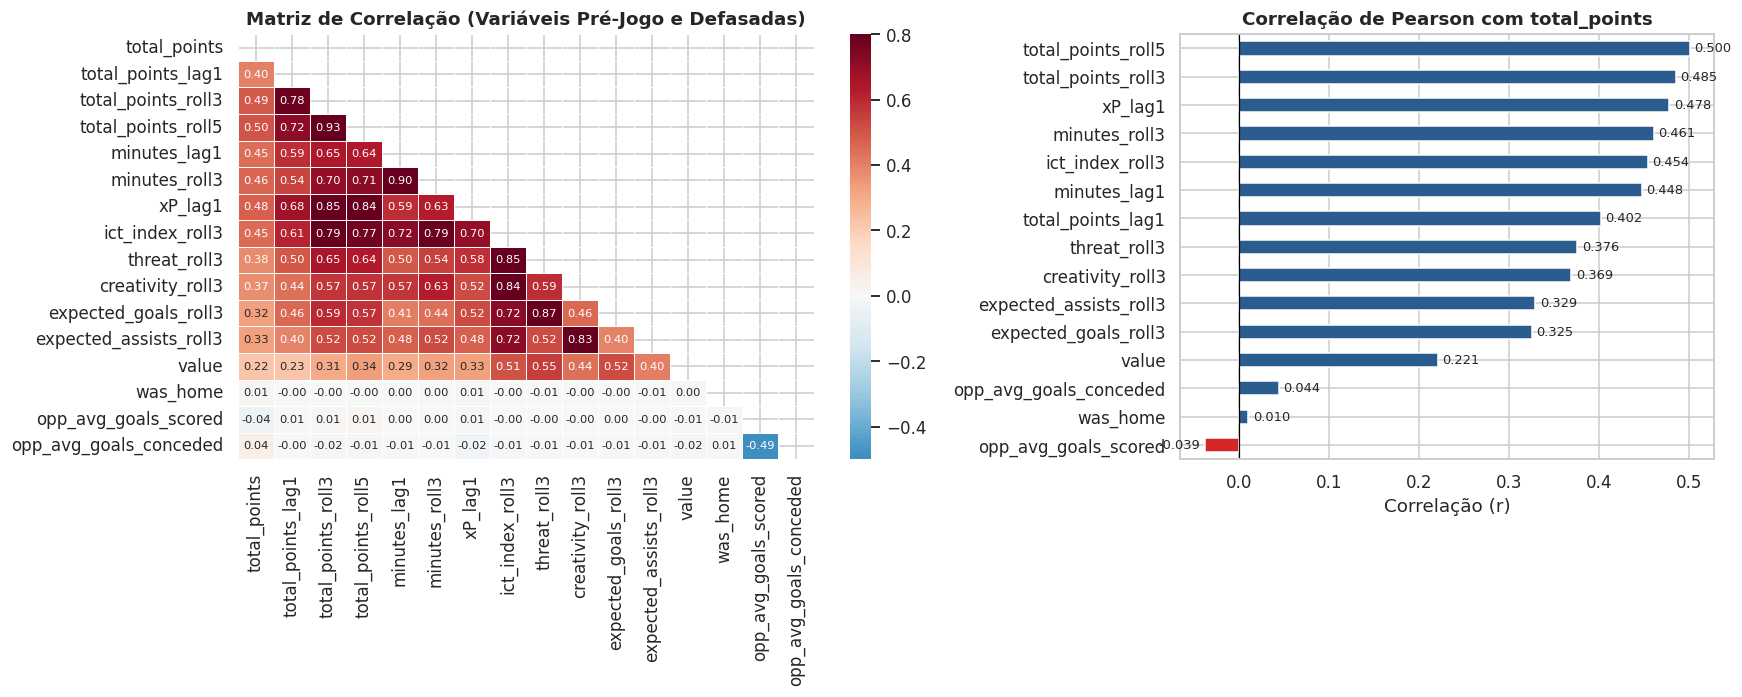

Top 5 correlações positivas com total_points:
total_points_roll5    0.5004
total_points_roll3    0.4853
xP_lag1               0.4779
minutes_roll3         0.4606
ict_index_roll3       0.4540


In [16]:
corr_cols = [
    'total_points', 'total_points_lag1', 'total_points_roll3', 'total_points_roll5',
    'minutes_lag1', 'minutes_roll3', 'xP_lag1', 'ict_index_roll3',
    'threat_roll3', 'creativity_roll3', 'expected_goals_roll3',
    'expected_assists_roll3', 'value', 'was_home',
    'opp_avg_goals_scored', 'opp_avg_goals_conceded'
]

corr_mat = df[corr_cols].corr()
target_corr = corr_mat['total_points'].drop('total_points').sort_values(ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={'width_ratios': [1.35, 1]})

# Heatmap
mask = np.triu(np.ones_like(corr_mat, dtype=bool))
sns.heatmap(
    corr_mat, mask=mask, cmap='RdBu_r', center=0, vmin=-0.5, vmax=0.8,
    annot=True, fmt='.2f', annot_kws={'size': 7.5}, linewidths=0.4, ax=axes[0]
)
axes[0].set_title('Matriz de Correlação (Variáveis Pré-Jogo e Defasadas)', fontsize=12, fontweight='bold')

# Barras com correlação direta com total_points
colors = ['#d62728' if v < 0 else '#2b5c8f' for v in target_corr.values]
target_corr.plot(kind='barh', color=colors, ax=axes[1])
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_title('Correlação de Pearson com total_points', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Correlação (r)')
for i, v in enumerate(target_corr.values):
    axes[1].text(v + (0.005 if v >= 0 else -0.005), i, f'{v:.3f}',
                 va='center', ha='left' if v >= 0 else 'right', fontsize=8.5)

plt.tight_layout()
plt.show()

print('Top 5 correlações positivas com total_points:')
print(target_corr.sort_values(ascending=False).head(5).round(4).to_string())

### 3.3 - Evolução Temporal por Faixa de Preço (`value`)

Analisamos a pontuação média ao longo das 38 rodadas separando os jogadores (excluindo `AM`) em quatro faixas de preço em milhões de libras (`£m`): **Econômico** (`<= £4.5m`), **Intermediário** (`£4.6m–£6.0m`), **Alto** (`£6.1m–£8.5m`) e **Premium** (`> £8.5m`).

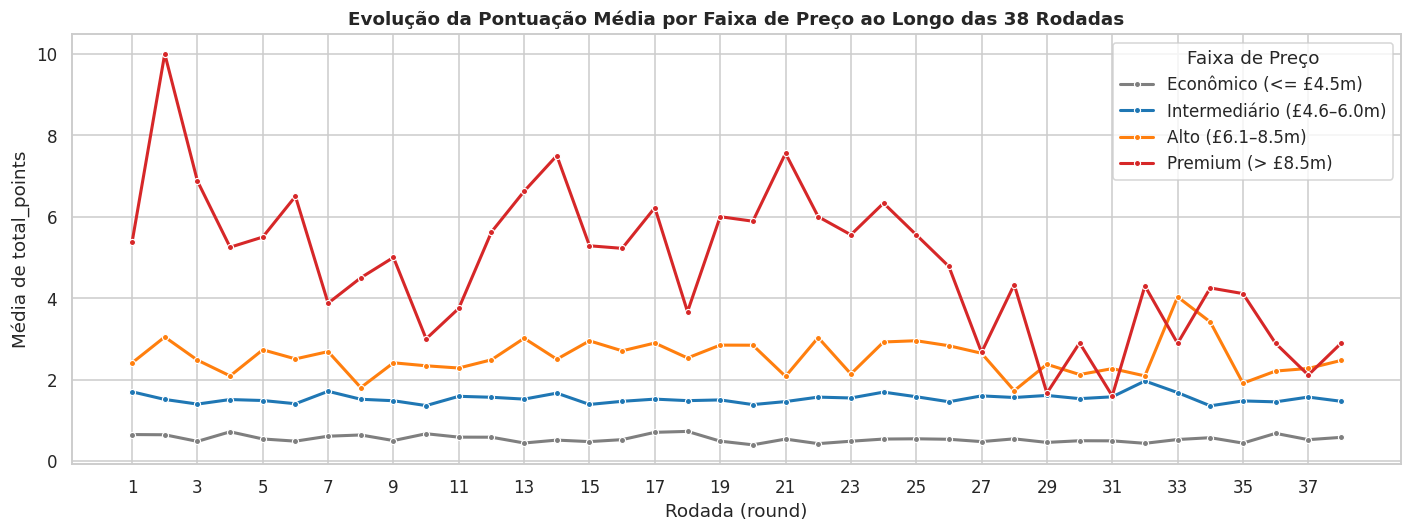

Média geral de total_points por faixa de preço:
                           count   mean    std
price_tier                                    
Econômico (<= £4.5m)       13665  0.541  1.558
Intermediário (£4.6–6.0m)  10469  1.535  2.465
Alto (£6.1–8.5m)            2464  2.545  3.368
Premium (> £8.5m)            321  4.826  5.170


In [17]:
df_players = df[df['position'] != 'AM'].copy()
df_players['price_m'] = df_players['value'] / 10.0

bins = [0, 4.5, 6.0, 8.5, 20.0]
labels = ['Econômico (<= £4.5m)', 'Intermediário (£4.6–6.0m)', 'Alto (£6.1–8.5m)', 'Premium (> £8.5m)']
df_players['price_tier'] = pd.cut(df_players['price_m'], bins=bins, labels=labels)

round_tier = (
    df_players.groupby(['round', 'price_tier'], observed=True)['total_points']
    .mean()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(13, 5))
palette = {'Econômico (<= £4.5m)': '#7f7f7f',
           'Intermediário (£4.6–6.0m)': '#1f77b4',
           'Alto (£6.1–8.5m)': '#ff7f0e',
           'Premium (> £8.5m)': '#d62728'}

sns.lineplot(
    data=round_tier, x='round', y='total_points', hue='price_tier',
    palette=palette, marker='o', markersize=4, linewidth=2, ax=ax
)
ax.set_title('Evolução da Pontuação Média por Faixa de Preço ao Longo das 38 Rodadas', fontsize=12, fontweight='bold')
ax.set_xlabel('Rodada (round)')
ax.set_ylabel('Média de total_points')
ax.set_xticks(range(1, 39, 2))
ax.legend(title='Faixa de Preço', loc='upper right')

plt.tight_layout()
plt.show()

print('Média geral de total_points por faixa de preço:')
print(df_players.groupby('price_tier', observed=True)['total_points'].agg(['count', 'mean', 'std']).round(3).to_string())

### 3.4 - Impacto do Mando de Campo (`was_home`) e da Posição (`position`)

Comparamos a distribuição de `total_points` por posição e avaliamos a vantagem de jogar em casa (`was_home = True`) com fora (`was_home = False`), tanto na base completa quanto entre jogadores que atuaram (`minutes > 0`).

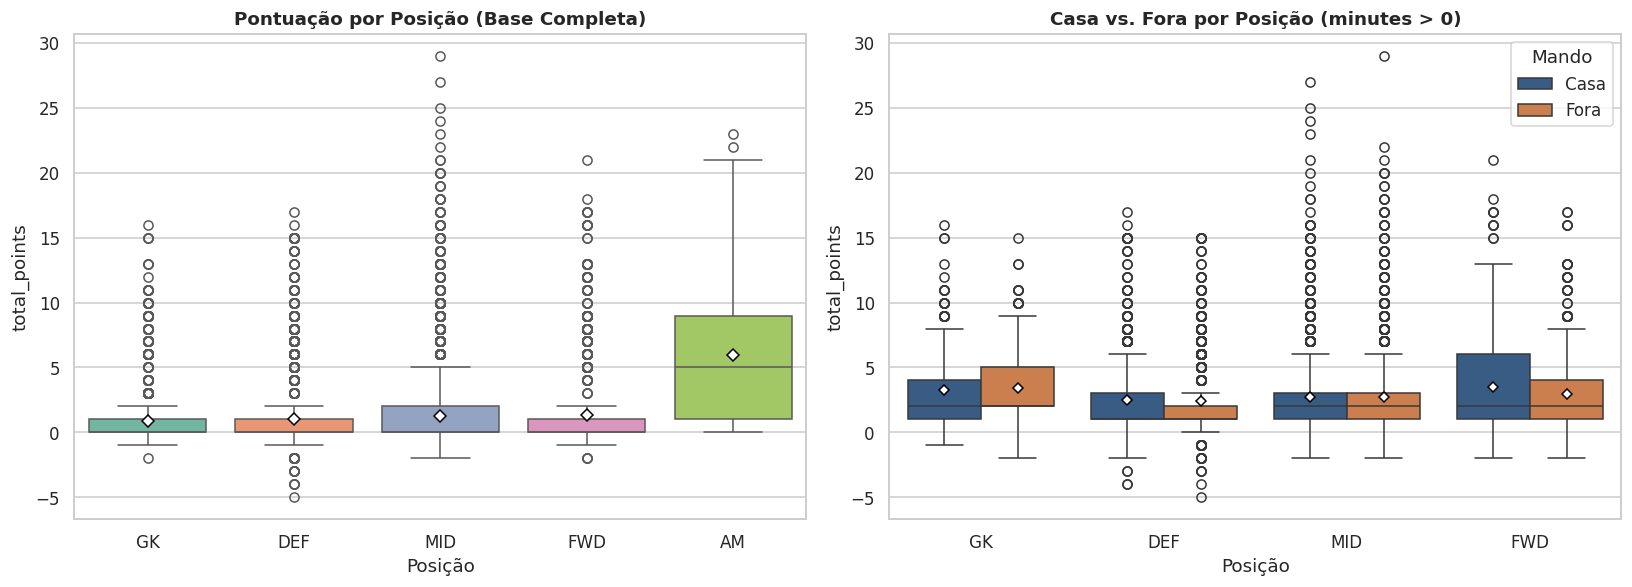

Média de total_points (Casa vs. Fora) — Base completa:
          count   mean    std
was_home                     
False     13665  1.193  2.416
True      13566  1.242  2.517

Média de total_points (Casa vs. Fora) por posição — minutes > 0:
Mando      Casa   Fora
position              
DEF       2.489  2.430
FWD       3.500  2.982
GK        3.271  3.428
MID       2.755  2.699


In [18]:
pos_order = ['GK', 'DEF', 'MID', 'FWD', 'AM']

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Boxplot por posição (base completa)
sns.boxplot(
    data=df, x='position', y='total_points', order=pos_order,
    showmeans=True,
    meanprops={'marker': 'D', 'markerfacecolor': 'white', 'markeredgecolor': 'black', 'markersize': 6},
    palette='Set2', ax=axes[0]
)
axes[0].set_title('Pontuação por Posição (Base Completa)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Posição')
axes[0].set_ylabel('total_points')

# Boxplot Casa vs Fora por posição (apenas jogadores que atuaram: minutes > 0)
df_act_pos = df[df['minutes'] > 0].copy()
df_act_pos['Mando'] = df_act_pos['was_home'].map({True: 'Casa', False: 'Fora'})

sns.boxplot(
    data=df_act_pos, x='position', y='total_points', hue='Mando',
    order=['GK', 'DEF', 'MID', 'FWD'], showmeans=True,
    meanprops={'marker': 'D', 'markerfacecolor': 'white', 'markeredgecolor': 'black', 'markersize': 5},
    palette={'Casa': '#2b5c8f', 'Fora': '#e07b39'}, ax=axes[1]
)
axes[1].set_title('Casa vs. Fora por Posição (minutes > 0)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Posição')
axes[1].set_ylabel('total_points')
axes[1].legend(title='Mando')

plt.tight_layout()
plt.show()

print('Média de total_points (Casa vs. Fora) — Base completa:')
print(df.groupby('was_home')['total_points'].agg(['count', 'mean', 'std']).round(3).to_string())
print('\nMédia de total_points (Casa vs. Fora) por posição — minutes > 0:')
print(df_act_pos.groupby(['position', 'Mando'])['total_points'].mean().unstack().round(3).to_string())

### 3.5 - Síntese dos Padrões Identificados

- **Concentração em zeros e cauda longa:** A distribuição de `total_points` apresenta forte pico em `0–2` pontos (`87,11%` da base) e apenas `115` observações (`0,42%`) com `15` ou mais pontos. Ao filtrar `minutes > 0`, a densidade desloca-se para a faixa de `1–3` pontos (média `2,74` vs. `1,22` na base completa).
- **Poder preditivo do histórico recente:** As maiores correlações lineares com `total_points` vêm das médias móveis e variáveis defasadas: `total_points_roll5` (`r = 0,500`), `total_points_roll3` (`r = 0,485`), `xP_lag1` (`r = 0,478`), `minutes_roll3` (`r = 0,461`) e `ict_index_roll3` (`r = 0,454`).
- **Relação preço vs. pontuação:** Há uma separação clara e consistente ao longo das 38 rodadas entre as faixas de preço, em que jogadores **Premium (`> £8.5m`)** têm média `4,826` pontos, seguidos por **Alto (`£6.1–8.5m`)** com `2,545`, **Intermediário (`£4.6–6.0m`)** com `1,535` e **Econômico (`<= £4.5m`)** com `0,541`.
- **Mando de campo e posição:** Na base completa, jogos em casa têm média ligeiramente maior (`1,242` vs. `1,193` fora). Entre jogadores que atuaram (`minutes > 0`), o efeito do mando é mais forte para atacantes (`FWD`: `3,500` em casa vs. `2,982` fora), moderado em `MID` (`2,755` vs. `2,699`) e `DEF` (`2,489` vs. `2,430`), e levemente invertido para goleiros (`GK`: `3,271` em casa vs. `3,428` fora, possivelmente por maior volume de defesas fora de casa).

---

## Etapa 4 - Definição Formal do Problema e Divisão Temporal

Nesta etapa formalizamos a tarefa de modelagem e preparamos os conjuntos de treino e teste respeitando a estrutura temporal dos dados:

1. **[4.1]** Enquadramento formal: Aprendizado Supervisionado de Regressão em dados em painel
2. **[4.2]** Seleção estrita de *features* pré-jogo, codificação e tratamento de NaNs iniciais
3. **[4.3]** Divisão temporal (rodadas `1–28` para treino, `29–38` para teste) e comparação das distribuições

### 4.1 - Enquadramento Formal do Problema

- **Tipo de Aprendizado:** **Aprendizado Supervisionado**, pois possuímos a variável alvo observada (`total_points`) para cada par `(jogador, rodada)`.
- **Tarefa:** **Regressão**, já que `total_points` é uma pontuação numérica (variando de `-5` a `29` na base) e o objetivo prático no Fantasy Premier League é estimar a pontuação esperada para ranquear e escalar jogadores, e não apenas separá-los em classes ou agrupamentos não supervisionados.
- **Estrutura dos Dados:** **Dados em painel (séries temporais múltiplas)** com `804` jogadores acompanhados ao longo de até `38` rodadas. Como as observações de um mesmo jogador e de rodadas próximas possuem dependência temporal, **é proibido usar `train_test_split` aleatório**, pois isso causaria vazamento de informação futura (*data leakage*) do conjunto de teste para o treino.

### 4.2 - Seleção de Features Pré-Jogo e Tratamento de NaNs Iniciais

Selecionamos exclusivamente variáveis disponíveis antes do início da rodada $t$:

- **Pré-jogo:** `value`, `selected`, `transfers_in`, `transfers_out`, `transfers_balance`, `xP_lag1`
- **Histórico do jogador (`_roll3`, `_roll5`, `_lag1`):** desempenho recente calculado estritamente até $t-1$
- **Contexto do adversário e partida:** `was_home`, `opp_avg_goals_scored`, `opp_avg_goals_conceded`, `position`

As primeiras aparições de cada jogador (rodada `1` ou primeira rodada após contratação no meio da temporada) não possuem histórico anterior (`NaN` nas *rolling/lag features*), sendo removidas para manter a consistência da modelagem.

In [19]:
if 'df' not in globals():
    df = pd.read_csv('fpl_prepared.csv')

rolling_lag_cols = [c for c in df.columns if '_roll' in c or '_lag1' in c]
pre_game_cols = ['value', 'selected', 'transfers_in', 'transfers_out', 'transfers_balance']
context_cols = ['was_home', 'opp_avg_goals_scored', 'opp_avg_goals_conceded', 'position']

raw_feature_cols = pre_game_cols + rolling_lag_cols + context_cols
# Remover duplicatas preservando ordem (caso xP_lag1 apareça em ambas)
raw_feature_cols = list(dict.fromkeys(raw_feature_cols))

n_before = len(df)
df_model = df.dropna(subset=raw_feature_cols).copy()
n_after = len(df_model)

# Codificação de variáveis categóricas/booleanas
df_model['was_home'] = df_model['was_home'].astype(int)
df_model = pd.get_dummies(df_model, columns=['position'], prefix='pos', dtype=int)

pos_dummy_cols = sorted([c for c in df_model.columns if c.startswith('pos_')])
feature_cols = [c for c in raw_feature_cols if c != 'position'] + pos_dummy_cols

print(f'Observações antes da limpeza de NaNs iniciais : {n_before:,}')
print(f'Observações removidas (sem histórico prévio)   : {n_before - n_after:,} ({(n_before - n_after)/n_before*100:.2f}%)')
print(f'Observações válidas para modelagem             : {n_after:,}')
print(f'Total de features finais (X)                   : {len(feature_cols)}')
print(f'Dummies de posição criadas                     : {pos_dummy_cols}')

Observações antes da limpeza de NaNs iniciais : 27,231
Observações removidas (sem histórico prévio)   : 804 (2.95%)
Observações válidas para modelagem             : 26,427
Total de features finais (X)                   : 38
Dummies de posição criadas                     : ['pos_AM', 'pos_DEF', 'pos_FWD', 'pos_GK', 'pos_MID']


### 4.3 - Divisão Temporal: Treino (Rodadas 1–28) vs. Teste (Rodadas 29–38)

Aplicamos um corte estritamente cronológico por `round`:
- **Treino:** rodadas `1` a `28` (na prática `2` a `28` após remoção da 1ª rodada sem histórico)
- **Teste:** rodadas `29` a `38` (últimas 10 rodadas da temporada, simulando previsão futura real)

=== Resumo da Divisão Temporal ===
Treino (rodadas 2–28): 18,771 linhas (71.0%), 38 features
Teste  (rodadas 29–38): 7,656 linhas (29.0%), 38 features


,Treino (1–28),Teste (29–38)
n_obs,18771.000,7656.000
mean,1.217,1.218
std,2.448,2.523
median,0.000,0.000
pct_zeros (%),58.969,61.403
pct_10plus (%),1.822,2.155


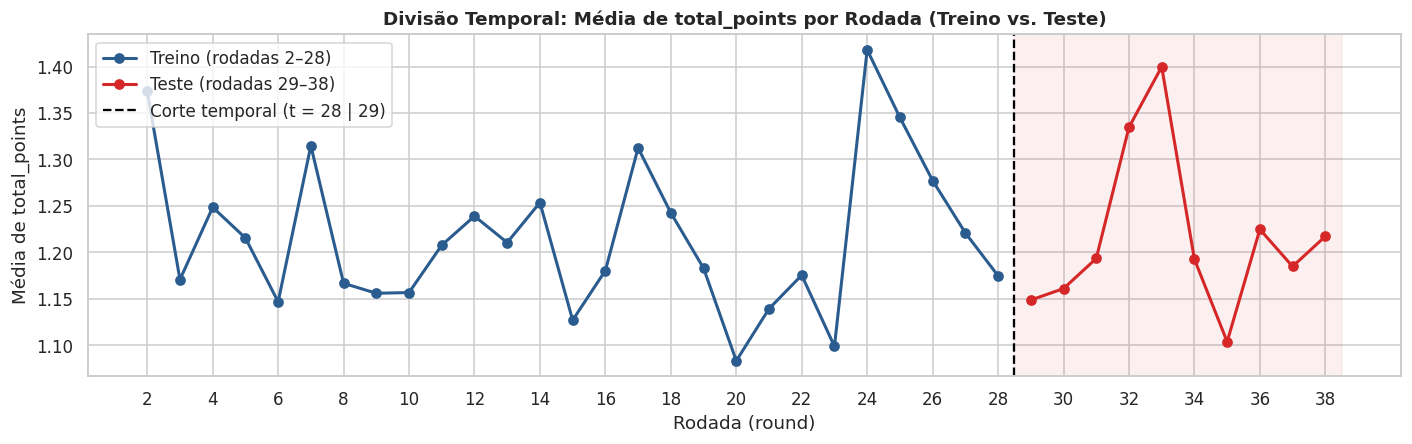

In [20]:
train_df = df_model[df_model['round'] <= 28].sort_values(['round', 'element']).reset_index(drop=True)
test_df  = df_model[df_model['round'] >= 29].sort_values(['round', 'element']).reset_index(drop=True)

X_train, y_train = train_df[feature_cols], train_df['total_points']
X_test, y_test   = test_df[feature_cols], test_df['total_points']

n_tot = len(df_model)
print('=== Resumo da Divisão Temporal ===')
print(f'Treino (rodadas {train_df["round"].min()}–{train_df["round"].max()}): {X_train.shape[0]:,} linhas ({X_train.shape[0]/n_tot*100:.1f}%), {X_train.shape[1]} features')
print(f'Teste  (rodadas {test_df["round"].min()}–{test_df["round"].max()}): {X_test.shape[0]:,} linhas ({X_test.shape[0]/n_tot*100:.1f}%), {X_test.shape[1]} features')

split_summary = pd.DataFrame({
    'Treino (1–28)': [
        len(y_train), y_train.mean(), y_train.std(), y_train.median(),
        (y_train == 0).mean() * 100, (y_train >= 10).mean() * 100
    ],
    'Teste (29–38)': [
        len(y_test), y_test.mean(), y_test.std(), y_test.median(),
        (y_test == 0).mean() * 100, (y_test >= 10).mean() * 100
    ]
}, index=['n_obs', 'mean', 'std', 'median', 'pct_zeros (%)', 'pct_10plus (%)'])

display(split_summary.round(3))

# Visualização da divisão temporal ao longo das 38 rodadas
round_means = df_model.groupby('round')['total_points'].mean()

fig, ax = plt.subplots(figsize=(13, 4.2))
ax.plot(round_means.loc[:28].index, round_means.loc[:28].values,
        marker='o', color='#2b5c8f', linewidth=2, label='Treino (rodadas 2–28)')
ax.plot(round_means.loc[29:].index, round_means.loc[29:].values,
        marker='o', color='#d62728', linewidth=2, label='Teste (rodadas 29–38)')
ax.axvline(28.5, color='black', linestyle='--', linewidth=1.5, label='Corte temporal (t = 28 | 29)')
ax.axvspan(28.5, 38.5, color='#d62728', alpha=0.07)
ax.set_title('Divisão Temporal: Média de total_points por Rodada (Treino vs. Teste)', fontsize=12, fontweight='bold')
ax.set_xlabel('Rodada (round)')
ax.set_ylabel('Média de total_points')
ax.set_xticks(range(2, 39, 2))
ax.legend()
plt.tight_layout()
plt.show()

---

## Etapa 5 - Ajuste e Seleção de Modelos

Treinamos quatro modelos com complexidade crescente, todos avaliados exclusivamente no conjunto de **teste (rodadas 29–38)**:

1. **Baseline ingênuo** - repete a pontuação da rodada anterior (`total_points_lag1`)
2. **Regressão Ridge** - modelo linear regularizado
3. **Random Forest** - ensemble de árvores via *bagging*
4. **LightGBM** - ensemble via *gradient boosting*

A seleção de hiperparâmetros usa `TimeSeriesSplit` para respeitar a ordem temporal.

In [21]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
import lightgbm as lgb

print('Bibliotecas de modelagem carregadas.')

Bibliotecas de modelagem carregadas.


### 5.1 - Baseline Ingênuo

O *baseline* mais simples: prever que o jogador fará a mesma pontuação da rodada anterior.
Serve como referência mínima — qualquer modelo útil deve superar este resultado.

In [22]:
# Baseline: y_pred = total_points_lag1 (pontuação da rodada anterior)
y_pred_baseline = X_test['total_points_lag1'].fillna(y_train.mean())

rmse_bl = root_mean_squared_error(y_test, y_pred_baseline)
mae_bl  = mean_absolute_error(y_test, y_pred_baseline)
r2_bl   = r2_score(y_test, y_pred_baseline)

print('=== Baseline Ingênuo (lag1) ===')
print(f'  RMSE : {rmse_bl:.4f}')
print(f'  MAE  : {mae_bl:.4f}')
print(f'  R²   : {r2_bl:.4f}')

=== Baseline Ingênuo (lag1) ===
  RMSE : 2.7337
  MAE  : 1.2133
  R²   : -0.1740


### 5.2 - Regressão Ridge

Modelo linear com regularização L2. Requer padronização das *features* (via `StandardScaler`) para que o parâmetro `alpha` atue de forma equilibrada entre atributos em escalas distintas.
O hiperparâmetro `alpha` é ajustado por `RandomizedSearchCV` com `TimeSeriesSplit`.

In [23]:
tscv = TimeSeriesSplit(n_splits=5)

ridge_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model',  Ridge())
])

ridge_search = RandomizedSearchCV(
    ridge_pipe,
    param_distributions={'model__alpha': [0.01, 0.1, 1, 10, 50, 100, 500, 1000]},
    n_iter=8,
    scoring='neg_root_mean_squared_error',
    cv=tscv,
    random_state=42,
    n_jobs=-1
)
ridge_search.fit(X_train, y_train)

best_ridge = ridge_search.best_estimator_
y_pred_ridge = best_ridge.predict(X_test)

rmse_ri = root_mean_squared_error(y_test, y_pred_ridge)
mae_ri  = mean_absolute_error(y_test, y_pred_ridge)
r2_ri   = r2_score(y_test, y_pred_ridge)

print(f'Melhor alpha : {ridge_search.best_params_["model__alpha"]}')
print(f'=== Ridge ===')
print(f'  RMSE : {rmse_ri:.4f}')
print(f'  MAE  : {mae_ri:.4f}')
print(f'  R²   : {r2_ri:.4f}')

Melhor alpha : 1000
=== Ridge ===
  RMSE : 2.0466
  MAE  : 1.0632
  R²   : 0.3420


### 5.3 - Random Forest

Ensemble de árvores de decisão treinadas em subamostras independentes (*bagging*). Captura relações não-lineares e interações entre *features* sem necessidade de padronização.

In [24]:
rf_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_distributions={
        'n_estimators': [100, 200, 300],
        'max_depth':    [None, 8, 12, 16],
        'min_samples_leaf': [1, 5, 10],
        'max_features': ['sqrt', 0.5],
    },
    n_iter=20,
    scoring='neg_root_mean_squared_error',
    cv=tscv,
    random_state=42,
    n_jobs=-1
)
rf_search.fit(X_train, y_train)

best_rf = rf_search.best_estimator_
y_pred_rf = best_rf.predict(X_test)

rmse_rf = root_mean_squared_error(y_test, y_pred_rf)
mae_rf  = mean_absolute_error(y_test, y_pred_rf)
r2_rf   = r2_score(y_test, y_pred_rf)

print(f'Melhores hiperparâmetros: {rf_search.best_params_}')
print(f'=== Random Forest ===')
print(f'  RMSE : {rmse_rf:.4f}')
print(f'  MAE  : {mae_rf:.4f}')
print(f'  R²   : {r2_rf:.4f}')

Melhores hiperparâmetros: {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 8}
=== Random Forest ===
  RMSE : 2.0280
  MAE  : 0.9993
  R²   : 0.3539


### 5.4 - LightGBM

Algoritmo de *gradient boosting* baseado em árvores com folhas (*leaf-wise*). Geralmente oferece boa performance com menor tempo de treinamento em comparação ao XGBoost.

In [25]:
lgbm_search = RandomizedSearchCV(
    lgb.LGBMRegressor(random_state=42, verbose=-1, n_jobs=-1),
    param_distributions={
        'n_estimators':   [100, 200, 400],
        'learning_rate':  [0.01, 0.05, 0.1],
        'max_depth':      [-1, 6, 10],
        'num_leaves':     [31, 63, 127],
        'subsample':      [0.6, 0.8, 1.0],
        'colsample_bytree': [0.6, 0.8, 1.0],
    },
    n_iter=20,
    scoring='neg_root_mean_squared_error',
    cv=tscv,
    random_state=42,
    n_jobs=-1
)
lgbm_search.fit(X_train, y_train)

best_lgbm = lgbm_search.best_estimator_
y_pred_lgbm = best_lgbm.predict(X_test)

rmse_lgbm = root_mean_squared_error(y_test, y_pred_lgbm)
mae_lgbm  = mean_absolute_error(y_test, y_pred_lgbm)
r2_lgbm   = r2_score(y_test, y_pred_lgbm)

print(f'Melhores hiperparâmetros: {lgbm_search.best_params_}')
print(f'=== LightGBM ===')
print(f'  RMSE : {rmse_lgbm:.4f}')
print(f'  MAE  : {mae_lgbm:.4f}')
print(f'  R²   : {r2_lgbm:.4f}')

Melhores hiperparâmetros: {'subsample': 0.8, 'num_leaves': 63, 'n_estimators': 100, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
=== LightGBM ===
  RMSE : 2.0223
  MAE  : 0.9964
  R²   : 0.3575


### 5.5 - Resumo da Etapa 5

In [26]:
# Tabela comparativa dos modelos no conjunto de teste
results = pd.DataFrame({
    'Modelo':  ['Baseline (lag1)', 'Ridge', 'Random Forest', 'LightGBM'],
    'RMSE':    [rmse_bl, rmse_ri, rmse_rf, rmse_lgbm],
    'MAE':     [mae_bl,  mae_ri,  mae_rf,  mae_lgbm],
    'R2':      [r2_bl,   r2_ri,   r2_rf,   r2_lgbm],
})
results = results.sort_values('RMSE').reset_index(drop=True)
print('=== Comparação no Conjunto de Teste (rodadas 29–38) ===')
display(results.round(4))

=== Comparação no Conjunto de Teste (rodadas 29–38) ===


,Modelo,RMSE,MAE,R2
0,LightGBM,2.0223,0.9964,0.3575
1,Random Forest,2.0280,0.9993,0.3539
2,Ridge,2.0466,1.0632,0.3420
3,Baseline (lag1),2.7337,1.2133,-0.1740
